In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def show(images, titles, cmap='gray', tamanho = 4):
  n = len(images)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(images[i], cmap=cmap)
    plt.title(titles[i])
    plt.axis('off')
  plt.show()

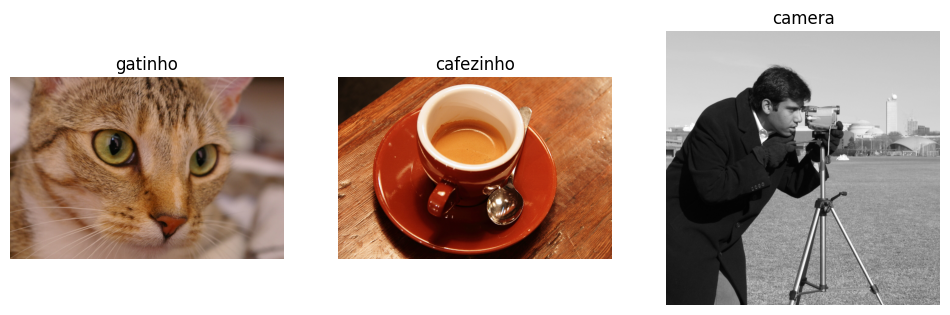

In [5]:
cat = data.cat()
coffee = data.coffee()
camera = data.camera()

show([cat, coffee, camera], ['gatinho', 'cafezinho', 'camera'])

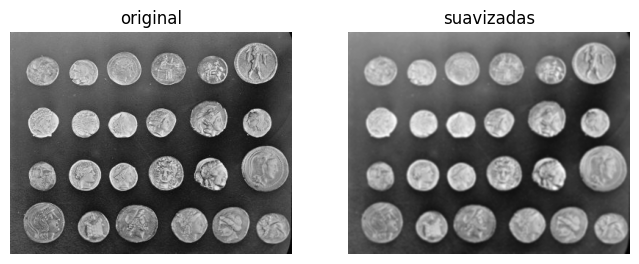

In [7]:
coins = data.coins()

coins_blur = cv2.GaussianBlur(coins, (5, 5), 0)

show([coins, coins_blur], ['original', 'suavizadas'])


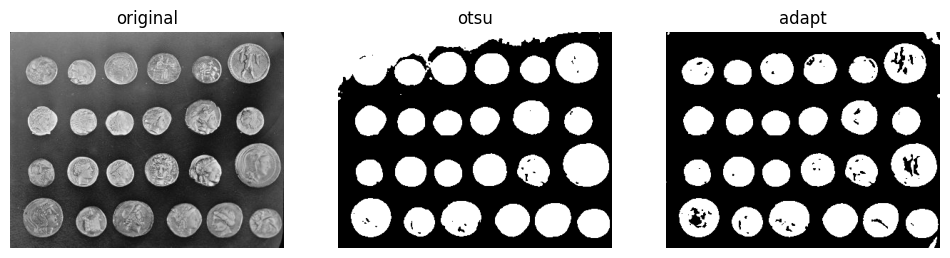

In [9]:
_, coins_otsu = cv2.threshold(coins_blur, 0, 255, cv2.THRESH_OTSU)
coins_adapt = cv2.adaptiveThreshold(coins_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 101, -10)

show([coins, coins_otsu, coins_adapt], ['original', 'otsu', 'adapt'])

In [12]:
contourns, _ = cv2.findContours(coins_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

contourns = [c for c in contourns if cv2.contourArea(c) > 500]
print('Quantidade de contornos:', len(contourns))

Quantidade de contornos: 24


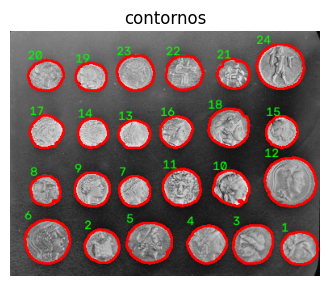

In [21]:
result = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB)
cv2.drawContours(result, contourns, -1, (255, 0, 0), 2)

for i, c in enumerate(contourns):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(result, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0))

show([result], ['contornos'])